# Assignment 7: Classification Analysis | Pair Assignment

**Goal:** build and compare a **Decision Tree** and a **Naive Bayes** classifier on your
group's dataset, then report what you found. EAch pair will choose one dataset from the following table and do the following.


Hints are provided in the cells marked `# TODO`. If you get stuck on syntax, check the code examples form this week.

> **Replace the loan_sample.cs with your chosen Kaggle dataset** and update the target column.

## Your dataset

| Group dataset | Example classification task | Target column | Kaggle link |
|---|---|---|---|
| SF Crime | Predict crime category, or district | `Category` / `PdDistrict` | https://www.kaggle.com/competitions/sf-crime/data
| NASA Asteroids | Predict if an asteroid is hazardous | `Hazardous` | https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
| Hotel Booking | Predict if a booking is cancelled, or hotel type | `is_canceled` / `hotel` | https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Use a Decision Tree for one task and Naive Bayes for the other (or, for Asteroids, run
both on the same task and compare). Keep notes as you go; you will need them for the report
at the bottom.

## Know your dataset before you start | Each pair will choose one of the following dataset

Read the block for your group's dataset first. It tells you what you are actually
predicting and the specific things to watch for at each step, so you are not surprised
halfway through.

### SF Crime, predicting crime category or district

**What you are figuring out:** can the time and place of an incident predict what kind of
crime it was, or which police district it happened in? You are turning raw incident logs
into useful predictors.

- **Exploration:** this file is huge (about 1 million rows). Take a random sample (say 50,000 rows) so your code runs fast. Check how many distinct crime categories exist.
- **Preprocessing:** the timestamp is not useful as text. Pull `hour`, `day of week`, and `month` out of it into their own numeric columns. If there are too many crime categories, group the rare ones into an "Other" bucket so the model is not splitting on dozens of tiny classes. Keep latitude and longitude; they are strong predictors.
- **Build models:** Decision Tree for one task (for example, category) and Naive Bayes for the other (district).
- **Evaluate:** with many classes, accuracy alone is thin. Look at the confusion matrix to see which categories get mixed up.

### NASA Asteroids, predicting hazardous (yes / no)

**What you are figuring out:** from an asteroid's size and orbital measurements, can you
predict whether NASA flags it as hazardous? This is the cleanest Decision Tree versus
Naive Bayes comparison of the three.

- **Exploration:** check the class balance first. Only about 16% are hazardous, so a model that always guesses "not hazardous" is already about 84% accurate. That is the baseline you must beat, and it is why accuracy alone will mislead you.
- **Preprocessing:** drop columns that carry no signal, such as `id` and `name`. The features are on very different scales (diameter versus orbital period), so apply feature scaling. This matters a lot for Naive Bayes.
- **Build models:** run both a Decision Tree and Naive Bayes on the same task and compare them directly.
- **Evaluate:** because the classes are imbalanced, report precision and recall for the "hazardous" class, not just accuracy. Recall matters most here: a missed hazardous asteroid is the costly error.

### Hotel Booking, predicting cancellation or hotel type

**What you are figuring out:** can booking details predict whether a reservation will be
cancelled, or whether it is a city versus resort hotel? This one is encoding-heavy.

- **Exploration:** check the cancellation rate (the classes may be imbalanced) and scan which columns are text versus numeric.
- **Preprocessing:** many columns are categorical and need encoding (`get_dummies` or `LabelEncoder`). Date columns are not useful raw; pull out useful pieces like the month. Watch for NULLs that are actually meaningful: a missing travel-agent value usually means "no agent," not bad data, so do not blindly drop those rows.
- **Build models:** Decision Tree for one task, Naive Bayes for the other.
- **Evaluate:** if cancellations are the minority class, look at precision and recall for cancellations, not just overall accuracy.

In [1]:
# Prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Ready.")

Ready.


## Step 1 - Data exploration

Load your data and get to know it: how many rows and columns, what the columns mean, and
how balanced the classes are. Class balance matters: if 90% of rows are one class, a model
can look accurate just by guessing that class every time.

In [2]:
# GIVEN: load the dataset. Change this path to your group's file when you have it.
df = pd.read_csv("train.csv")

# Set this to the name of the column you are predicting.
target = "Category"

df.head()

,Dates,Category,Descript,DayOfWeek,PdDistrict,Resolution,Address,X,Y
0,2015-05-13 23:53:00,WARRANTS,WARRANT ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",OAK ST / LAGUNA ST,-122.425892,37.774599
1,2015-05-13 23:53:00,OTHER OFFENSES,TRAFFIC VIOLATION ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",OAK ST / LAGUNA ST,-122.425892,37.774599
2,2015-05-13 23:33:00,OTHER OFFENSES,TRAFFIC VIOLATION ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",VANNESS AV / GREENWICH ST,-122.424363,37.800414
3,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,NORTHERN,NONE,1500 Block of LOMBARD ST,-122.426995,37.800873
4,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,PARK,NONE,100 Block of BRODERICK ST,-122.438738,37.771541


In [3]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[target].value_counts()
# Also try df.describe() for the numeric columns.

df.shape
df.info()
df[target].value_counts()


<class 'pandas.DataFrame'>
RangeIndex: 878049 entries, 0 to 878048
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Dates       878049 non-null  str    
 1   Category    878049 non-null  str    
 2   Descript    878049 non-null  str    
 3   DayOfWeek   878049 non-null  str    
 4   PdDistrict  878049 non-null  str    
 5   Resolution  878049 non-null  str    
 6   Address     878049 non-null  str    
 7   X           878049 non-null  float64
 8   Y           878049 non-null  float64
dtypes: float64(2), str(7)
memory usage: 60.3 MB


Category
LARCENY/THEFT                  174900
OTHER OFFENSES                 126182
NON-CRIMINAL                    92304
ASSAULT                         76876
DRUG/NARCOTIC                   53971
VEHICLE THEFT                   53781
VANDALISM                       44725
WARRANTS                        42214
BURGLARY                        36755
SUSPICIOUS OCC                  31414
MISSING PERSON                  25989
ROBBERY                         23000
FRAUD                           16679
FORGERY/COUNTERFEITING          10609
SECONDARY CODES                  9985
WEAPON LAWS                      8555
PROSTITUTION                     7484
TRESPASS                         7326
STOLEN PROPERTY                  4540
SEX OFFENSES FORCIBLE            4388
DISORDERLY CONDUCT               4320
DRUNKENNESS                      4280
RECOVERED VEHICLE                3138
KIDNAPPING                       2341
DRIVING UNDER THE INFLUENCE      2268
RUNAWAY                          1946
LIQ

## Step 2 - Preprocessing

Get the data ready for the models. You will typically need to:

- Drop columns that are just identifiers or are not useful (e.g. an ID column).
- Handle missing values (fill numeric columns with the median, text columns with the mode).
- Encode categorical (text) columns into numbers with `pd.get_dummies(...)` or `LabelEncoder`.
- Separate the target `y` from the features `X`, then split into train and test sets.

In [4]:
# TODO: drop unhelpful columns and handle missing values
# Hint: start from a copy -> data = df.drop(columns=["applicant_id"]).copy()
# Hint for missing values, loop over columns:
#   if pd.api.types.is_numeric_dtype(data[col]): fill with data[col].median()
#   else: fill with data[col].mode()[0]

sample = df.sample(50000, random_state=42)
data = sample.drop(columns=["PdDistrict"]).copy()

for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].median())
    else: 
        data[col] = data[col].fillna(data[col].mode()[0])


In [5]:
# TODO: build X (features) and y (target), then encode the categorical columns
# Hint: y = data[target]
# Hint: X = pd.get_dummies(data.drop(columns=[target]), drop_first=True)

y = data['Category']
X = pd.get_dummies(data.drop(columns=['Category']), drop_first=True)

In [6]:
# TODO: split into training and test sets
# Hint: X_train, X_test, y_train, y_test = train_test_split(
#           X, y, test_size=0.25, random_state=1, stratify=y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

## Step 3 - Build the models

Each classifier is only a few lines: create it, then call `.fit(X_train, y_train)`.

In [7]:
# TODO: train a Decision Tree
# Hint: dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
#       dtree.fit(X_train, y_train)

dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

In [8]:
# TODO: train a Naive Bayes classifier
# Hint: nb_model = GaussianNB()
#       nb_model.fit(X_train, y_train)

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](37,)","[ 74.,3279., 16.,...,2268.,1798., 375.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](37,)","[0. ,0.09,0. ,...,0.06,0.05,0.01]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U27](37,)","['ARSON','ASSAULT','BAD CHECKS',...,'VEHICLE THEFT','WARRANTS', 'WEAPON LAWS']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,2.398e-10
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](58402,)","['X','Y','Dates_2003-01-06 03:33:00',..., 'Address_YOSEMITE AV / JENNINGS ST','Address_ZOE ST / BRANNAN ST', 'Address_ZOE ST / FREELON ST']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,58402
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](37, 58402)","[[-122.43, 37.77, 0. ,..., 0. , 0. , 0. ], [-122.42, 37.76, 0. ,..., 0. , 0. , 0. ], [-122.42, 37.77, 0. ,..., 0. , 0. , 0. ], ..., [-122.43, 37.76, 0. ,..., 0. , 0. , 0. ], [-122.42, 37.77, 0. ,..., 0. , 0. , 0. ], [-122.42, 37.76, 0. ,..., 0. , 0. , 0. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](37, 58402)","[[0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.], ..., [0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.]]"


## Step 4 - Evaluate and compare

For **each** model, predict on the test set and report:

- accuracy (`accuracy_score`)
- the confusion matrix (`ConfusionMatrixDisplay.from_predictions`)
- precision, recall, and F1 (`classification_report`)

Then compare: which model is more accurate, and what do the precision and recall for the
class you care about tell you?

0.33464


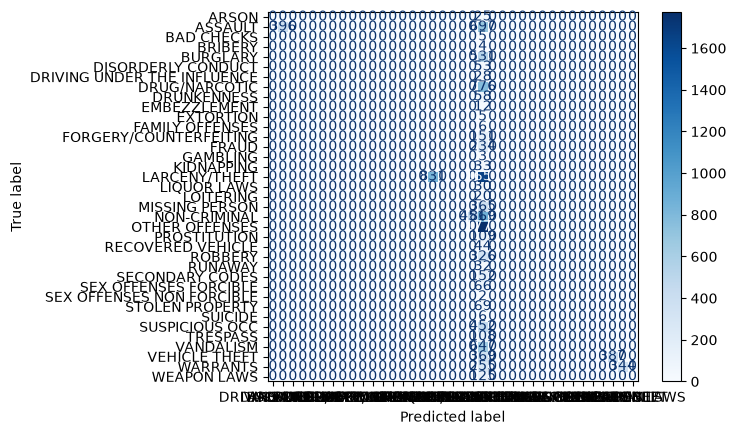

                             precision    recall  f1-score   support

                      ARSON       0.00      0.00      0.00        25
                    ASSAULT       1.00      0.36      0.53      1093
                 BAD CHECKS       0.00      0.00      0.00         5
                    BRIBERY       0.00      0.00      0.00         4
                   BURGLARY       0.00      0.00      0.00       531
         DISORDERLY CONDUCT       0.00      0.00      0.00        53
DRIVING UNDER THE INFLUENCE       0.00      0.00      0.00        28
              DRUG/NARCOTIC       0.00      0.00      0.00       776
                DRUNKENNESS       0.00      0.00      0.00        58
               EMBEZZLEMENT       0.00      0.00      0.00        12
                  EXTORTION       0.00      0.00      0.00         5
            FAMILY OFFENSES       0.00      0.00      0.00         6
     FORGERY/COUNTERFEITING       0.00      0.00      0.00       151
                      FRAUD      

c:\Users\xande\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\xande\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\xande\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

In [9]:
# TODO: evaluate the Decision Tree
# Hint: dt_pred = dtree.predict(X_test)
#       print(accuracy_score(y_test, dt_pred))
#       ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues"); plt.show()
#       print(classification_report(y_test, dt_pred))

dt_pred = dtree.predict(X_test)
print(accuracy_score(y_test, dt_pred))
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues"); plt.show()
print(classification_report(y_test, dt_pred))


0.71736


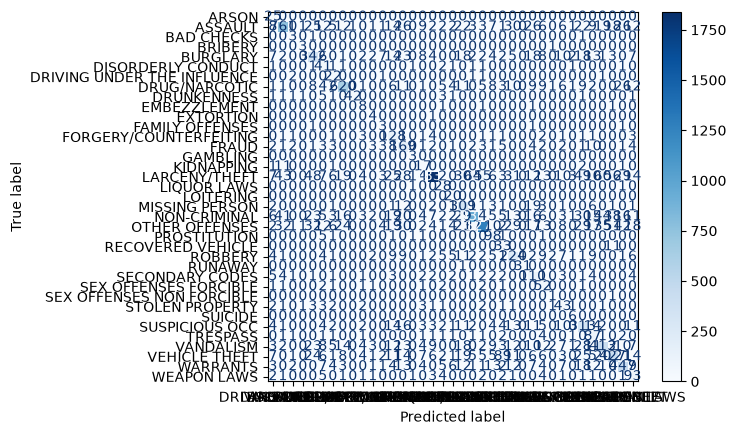

                             precision    recall  f1-score   support

                      ARSON       0.27      1.00      0.42        25
                    ASSAULT       0.84      0.70      0.76      1093
                 BAD CHECKS       0.20      0.60      0.30         5
                    BRIBERY       0.43      0.75      0.55         4
                   BURGLARY       0.64      0.64      0.64       531
         DISORDERLY CONDUCT       0.29      0.77      0.42        53
DRIVING UNDER THE INFLUENCE       0.31      0.79      0.44        28
              DRUG/NARCOTIC       0.86      0.80      0.83       776
                DRUNKENNESS       0.98      0.72      0.83        58
               EMBEZZLEMENT       0.22      0.67      0.33        12
                  EXTORTION       0.19      0.80      0.31         5
            FAMILY OFFENSES       0.12      0.50      0.19         6
     FORGERY/COUNTERFEITING       0.44      0.85      0.58       151
                      FRAUD      

In [10]:
# TODO: evaluate the Naive Bayes model (same steps as above)

nb_pred = nb_model.predict(X_test)
print(accuracy_score(y_test, nb_pred))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, cmap="Blues"); plt.show()
print(classification_report(y_test, nb_pred))


<BarContainer object of 3 artists>

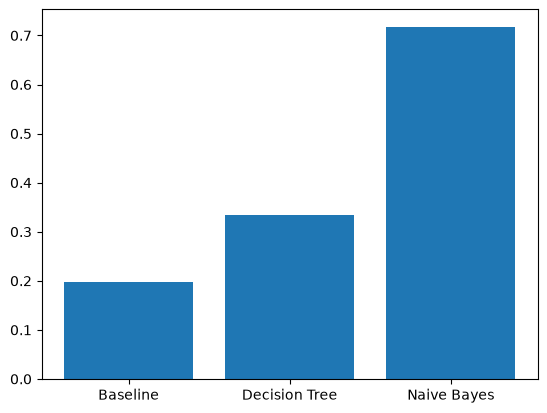

In [11]:
# TODO: compare the two models' accuracy against a baseline
# Hint: baseline = y_test.value_counts(normalize=True).max()
# A simple bar chart makes the comparison clear.

baseline = y_test.value_counts(normalize=True).max()

plt.bar(["Baseline", "Decision Tree", "Naive Bayes"], [baseline, accuracy_score(y_test, dt_pred), accuracy_score(y_test, nb_pred)])


## Step 5 - Findings

Write your answers here as you work.

1. **Preprocessing / data reduction** - what did you have to clean, drop, encode, or sample, and why?

   *Your answer:*
   I filled in any null values with the mean or mode depending on if it was a numerical cetegory or not. This was because partial data could throw off the prediction model. I dropped the districts column since, from what I understood of the instructions, I did not need it. I also only used about 50,000 rows from the data as a consistant sample since my computer would not be able to reasonably handle all of the data. I then encoded all columns beside both numerical and the Categories columns.

2. **Data used** - which features did you select as predictors, and why those?

   *Your answer:*
   I left the columns besides the district column in since from viewing the data and reading the instructions it seemed that all of it could be used for the prediction.

3. **Findings** - what did the analysis reveal about the data itself (patterns, surprises)?

   *Your answer:*
   It was kind of hard to read, probably because I probably could have taken from of the inputed columns out, but the biggest thing that surprised me was that the Naive Bayes was way better and more accurate compared to the other model used.

4. **Decision Tree vs Naive Bayes** - which performed better on your task, and what are the
   strengths and shortcomings of each one here?

   *Your answer:*
   The Naive Bayes definetly performed better. It had a higher accuracy but definitely took longer to load for me. The Decision Tree had a way lower accuracy but it was a lot faster to load.

5. **Challenges** - What was difficult, and how did you handle it?

   *Your answer:*
   The only big challenge was that my kernel died AGAIN. Thankfully JT had the same problem and helped me work through it.

   I also would like to say I did all of this with my partner, Zayne Roberts, even though I answered the questions primarily with "I" statements.

   One last thing. I removed the data files since git hub was not wanting it to push with it.

## Submission checklist

- This notebook (renamed `Last_First_Assignment7.ipynb`), with all cells run and output showing
- Link to your GitHub repository